# Scroll to the bottom of this notebook to see 
# Implementation of Gradient Boost


# Subset of the Lending Club Dataset

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import matplotlib.ticker as mticker  

from sklearn.model_selection import (
    train_test_split, 
    cross_val_score, 
    GridSearchCV, 
    RandomizedSearchCV, 
    RepeatedKFold
)

In [2]:
train = pd.read_csv('loan_sample_train.csv')
test = pd.read_csv('loan_sample_test.csv')

/opt/anaconda3/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3146: DtypeWarning: Columns (0) have mixed types.Specify dtype option on import or set low_memory=False.
  has_raised = await self.run_ast_nodes(code_ast.body, cell_name,


In [3]:
train['dataset_type'] = 'train'
test['dataset_type'] = 'test'

In [4]:
loan = pd.concat([train, test], ignore_index=True)

In [5]:
loan.head()

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term,target,dataset_type
0,1006259,NaN,2500.0,2500.0,2500.0,36 months,11.71,82.69,B,B3,...,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN,0,train
1,50303671,NaN,7425.0,7425.0,7425.0,36 months,18.55,270.49,E,E2,...,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN,0,train
2,30485774,NaN,15700.0,15700.0,15700.0,36 months,11.67,519.00,B,B4,...,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN,0,train
3,29183992,NaN,8450.0,8450.0,8450.0,36 months,18.99,309.71,E,E1,...,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN,0,train
4,62644235,NaN,15000.0,15000.0,15000.0,36 months,7.89,469.29,A,A5,...,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN,0,train


In [6]:
loan.info(verbose=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400000 entries, 0 to 399999
Data columns (total 153 columns):
 #   Column                                      Dtype  
---  ------                                      -----  
 0   id                                          object 
 1   member_id                                   float64
 2   loan_amnt                                   float64
 3   funded_amnt                                 float64
 4   funded_amnt_inv                             float64
 5   term                                        object 
 6   int_rate                                    float64
 7   installment                                 float64
 8   grade                                       object 
 9   sub_grade                                   object 
 10  emp_title                                   object 
 11  emp_length                                  object 
 12  home_ownership                              object 
 13  annual_inc                  

In [7]:
loan.describe()

,member_id,loan_amnt,funded_amnt,funded_amnt_inv,int_rate,installment,annual_inc,dti,delinq_2yrs,fico_range_low,...,hardship_amount,hardship_length,hardship_dpd,orig_projected_additional_accrued_interest,hardship_payoff_balance_amount,hardship_last_payment_amount,settlement_amount,settlement_percentage,settlement_term,target
count,0.0,399996.000000,399996.000000,399996.000000,399996.000000,399996.000000,3.999950e+05,399695.000000,399991.000000,399996.000000,...,1974.000000,1974.0,1974.000000,1529.000000,1974.000000,1974.000000,6047.000000,6047.000000,6047.000000,400000.000000
mean,NaN,15042.661614,15037.214622,15019.838961,13.092479,445.557073,7.777201e+04,18.859016,0.305924,698.669312,...,157.364985,3.0,13.852077,455.825160,11717.272077,197.921469,4958.388454,47.666661,13.231685,0.118795
std,NaN,9194.553141,9192.507485,9196.881776,4.829744,267.143635,7.290914e+04,14.260549,0.862388,33.078437,...,129.250101,0.0,9.579470,372.917724,7551.646125,204.989482,3632.065124,6.891209,8.392245,0.323548
min,NaN,600.000000,600.000000,0.000000,5.310000,4.930000,0.000000e+00,0.000000,0.000000,620.000000,...,1.610000,3.0,0.000000,15.150000,193.980000,0.010000,121.910000,0.550000,0.000000,0.000000
25%,NaN,8000.000000,8000.000000,8000.000000,9.490000,251.580000,4.600000e+04,11.920000,0.000000,675.000000,...,60.665000,3.0,6.000000,172.170000,5873.532500,45.990000,2171.000000,45.000000,6.000000,0.000000
50%,NaN,12887.500000,12850.000000,12800.000000,12.620000,377.870000,6.500000e+04,17.860000,0.000000,690.000000,...,122.975000,3.0,15.000000,354.390000,10170.715000,136.115000,4090.140000,45.000000,14.000000,0.000000
75%,NaN,20000.000000,20000.000000,20000.000000,15.990000,593.060000,9.300000e+04,24.520000,0.000000,715.000000,...,216.505000,3.0,22.000000,619.770000,16223.260000,286.992500,6850.420000,50.000000,18.000000,0.000000
max,NaN,40000.000000,40000.000000,40000.000000,30.990000,1719.830000,9.500000e+06,999.000000,26.000000,845.000000,...,845.220000,3.0,32.000000,2535.660000,36734.040000,1377.170000,27000.000000,95.130000,181.000000,1.000000


In [8]:
print(loan['loan_status'].value_counts())

Fully Paid                                             190445
Current                                                155398
Charged Off                                             47518
Late (31-120 days)                                       3797
In Grace Period                                          1546
Late (16-30 days)                                         794
Does not meet the credit policy. Status:Fully Paid        363
Does not meet the credit policy. Status:Charged Off       127
Default                                                     8
Name: loan_status, dtype: int64


In [9]:
# Encoding loan_status to binary (e.g. default = 1, paid = 0)
loan['target'] = loan['loan_status'].apply(lambda x: 1 if x == 'Charged Off' else 0)
loan['target'].value_counts()

0    352482
1     47518
Name: target, dtype: int64

In [10]:
num_non_default = loan['target'].value_counts().loc[0]
num_default = loan['target'].value_counts().loc[1]

In [11]:

percentage_default = num_default/(num_non_default + num_default)
print(f"percentage of default: {percentage_default}%")
print(f"percentage of good loans:{1-percentage_default}%")

percentage of default: 0.118795%
percentage of good loans:0.881205%


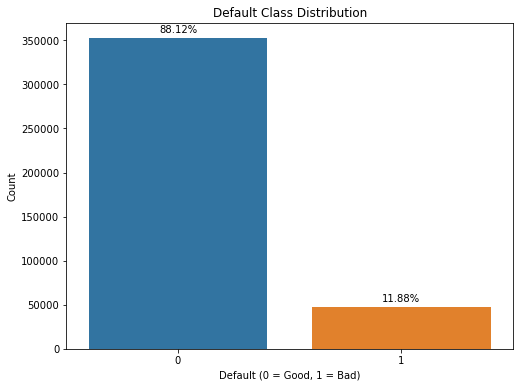

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
ax = sns.countplot(data=loan, x='target')

plt.title("Default Class Distribution")
plt.xlabel("Default (0 = Good, 1 = Bad)")
plt.ylabel("Count")


total = len(loan)

for p in ax.patches:
    count = p.get_height()
    percentage = f'{100 * count / total:.2f}%'
    x = p.get_x() + p.get_width() / 2
    y = p.get_height()
    ax.text(x, y + total * 0.01, percentage, ha='center', va='bottom')

plt.show()


In [13]:
corr_pos = loan.corr()['target'].sort_values(ascending=False)
selected_feature1 = corr_pos.index[:15]
corr_pos.head(30)

target                                1.000000
recoveries                            0.527865
collection_recovery_fee               0.500351
int_rate                              0.196810
hardship_dpd                          0.139277
sec_app_inq_last_6mths                0.099595
total_rec_late_fee                    0.094880
acc_open_past_24mths                  0.091665
inq_last_6mths                        0.082802
num_tl_op_past_12m                    0.080781
open_rv_24m                           0.078562
percent_bc_gt_75                      0.076978
bc_util                               0.074077
inq_last_12m                          0.071734
revol_util                            0.066941
all_util                              0.066602
open_acc_6m                           0.066531
open_rv_12m                           0.064712
open_il_24m                           0.058717
open_il_12m                           0.057999
il_util                               0.053981
num_actv_rev_

In [14]:
selected_feature1

Index(['target', 'recoveries', 'collection_recovery_fee', 'int_rate',
       'hardship_dpd', 'sec_app_inq_last_6mths', 'total_rec_late_fee',
       'acc_open_past_24mths', 'inq_last_6mths', 'num_tl_op_past_12m',
       'open_rv_24m', 'percent_bc_gt_75', 'bc_util', 'inq_last_12m',
       'revol_util'],
      dtype='object')

In [15]:
corr_neg = loan.corr()['target'].sort_values(ascending=True)
selected_feature2 = corr_neg.index[:15]
print(corr_neg.head(30))

last_fico_range_high                  -0.600920
last_fico_range_low                   -0.557002
total_rec_prncp                       -0.225445
out_prncp                             -0.210470
out_prncp_inv                         -0.210448
last_pymnt_amnt                       -0.180610
total_pymnt                           -0.140313
total_pymnt_inv                       -0.140197
fico_range_low                        -0.119775
fico_range_high                       -0.119773
sec_app_fico_range_low                -0.106761
sec_app_fico_range_high               -0.106761
bc_open_to_buy                        -0.081308
settlement_percentage                 -0.076661
total_bc_limit                        -0.072566
sec_app_mths_since_last_major_derog   -0.064402
tot_hi_cred_lim                       -0.063014
mths_since_recent_inq                 -0.059829
annual_inc_joint                      -0.059587
total_rev_hi_lim                      -0.058225
avg_cur_bal                           -0

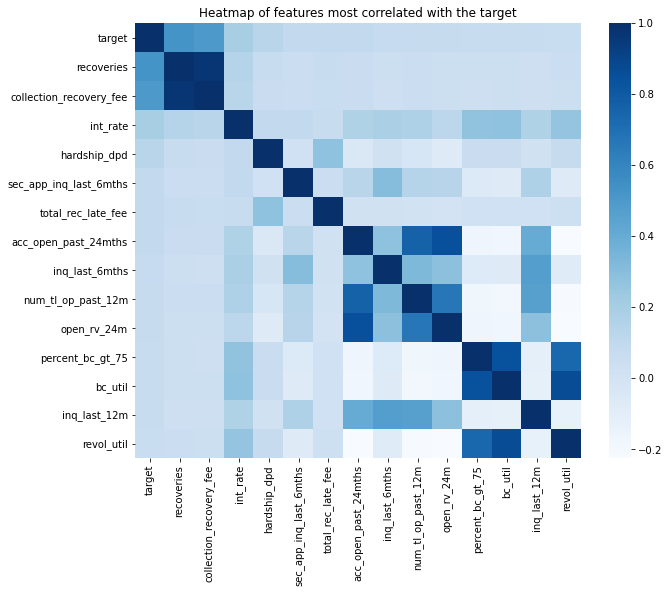

In [16]:
plt.figure(figsize=(10, 8))
sns.heatmap(loan[selected_feature1].corr(), cmap="Blues")
plt.title("Heatmap of features most correlated with the target")

None

In [17]:
missing_percent = loan.isnull().mean() * 100
missing_percent_sorted = missing_percent.sort_values(ascending=False)
missing_percent_sorted

member_id                                     100.00000
orig_projected_additional_accrued_interest     99.61775
hardship_amount                                99.50650
hardship_type                                  99.50650
hardship_reason                                99.50650
                                                ...    
disbursement_method                             0.00100
funded_amnt                                     0.00100
dataset_type                                    0.00000
target                                          0.00000
id                                              0.00000
Length: 153, dtype: float64

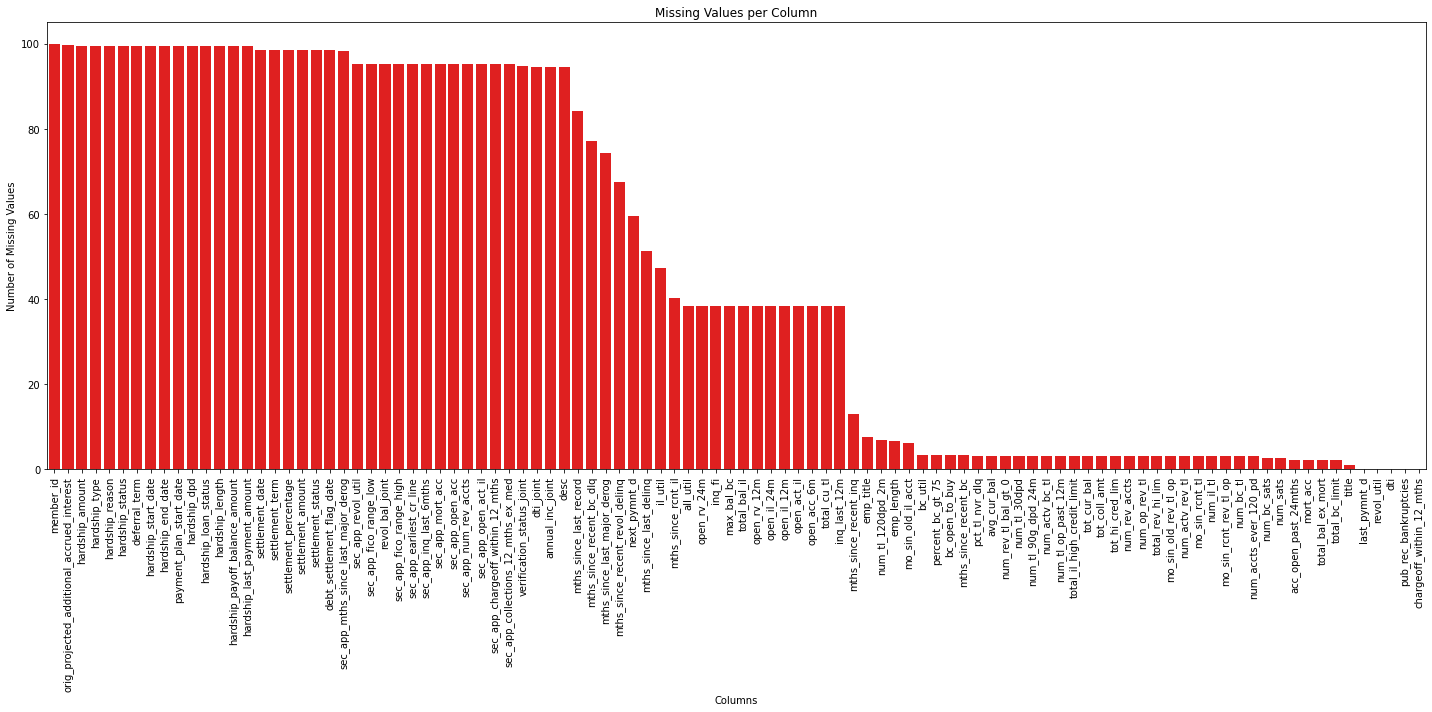

In [18]:
plt.figure(figsize=(20, 10))
sns.barplot(x=missing_percent_sorted.index[:100], y=missing_percent_sorted.values[:100], color="red")
plt.title("Missing Values per Column")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [19]:
unique = pd.DataFrame(loan.nunique(), columns=["Count"])
unique["Count"].sort_values(ascending=False)

id                 400000
url                399996
total_pymnt        344290
total_pymnt_inv    325282
total_rec_int      253061
                    ...  
hardship_length         1
policy_code             1
deferral_term           1
hardship_type           1
member_id               0
Name: Count, Length: 153, dtype: int64

In [20]:
nominal_columns = loan.select_dtypes(exclude=['number'])
nominal_columns

,id,term,grade,sub_grade,emp_title,emp_length,home_ownership,verification_status,issue_d,loan_status,...,hardship_start_date,hardship_end_date,payment_plan_start_date,hardship_loan_status,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,dataset_type
0,1006259,36 months,B,B3,NaN,2 years,OWN,Source Verified,Nov-2011,Fully Paid,...,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,train
1,50303671,36 months,E,E2,New Patient Check in,1 year,MORTGAGE,Source Verified,Jun-2015,Fully Paid,...,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,train
2,30485774,36 months,B,B4,RN,10+ years,MORTGAGE,Source Verified,Oct-2014,Fully Paid,...,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,train
3,29183992,36 months,E,E1,Assistant customer service manager,1 year,RENT,Not Verified,Oct-2014,Fully Paid,...,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,train
4,62644235,36 months,A,A5,Officer,< 1 year,OWN,Not Verified,Oct-2015,Fully Paid,...,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,train
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
399995,560678,36 months,C,C3,Associate Professor,4 years,MORTGAGE,Source Verified,Mar-2016,Fully Paid,...,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,test
399996,1625136,36 months,A,A5,WCND,10+ years,MORTGAGE,Not Verified,Oct-2012,Fully Paid,...,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,test
399997,136551975,60 months,C,C3,Assistant Pricipal,3 years,MORTGAGE,Verified,Jul-2018,Current,...,NaN,NaN,NaN,NaN,DirectPay,N,NaN,NaN,NaN,test
399998,122303361,36 months,B,B5,Office Assistant 2,10+ years,RENT,Source Verified,Nov-2017,Current,...,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,test


#### Now I will try to identify categorical features, both nominal categorical and ordinal categorical

In [21]:
nominal_columns = loan.select_dtypes(exclude=['number'])
nominal_columns

,id,term,grade,sub_grade,emp_title,emp_length,home_ownership,verification_status,issue_d,loan_status,...,hardship_start_date,hardship_end_date,payment_plan_start_date,hardship_loan_status,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,dataset_type
0,1006259,36 months,B,B3,NaN,2 years,OWN,Source Verified,Nov-2011,Fully Paid,...,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,train
1,50303671,36 months,E,E2,New Patient Check in,1 year,MORTGAGE,Source Verified,Jun-2015,Fully Paid,...,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,train
2,30485774,36 months,B,B4,RN,10+ years,MORTGAGE,Source Verified,Oct-2014,Fully Paid,...,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,train
3,29183992,36 months,E,E1,Assistant customer service manager,1 year,RENT,Not Verified,Oct-2014,Fully Paid,...,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,train
4,62644235,36 months,A,A5,Officer,< 1 year,OWN,Not Verified,Oct-2015,Fully Paid,...,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,train
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
399995,560678,36 months,C,C3,Associate Professor,4 years,MORTGAGE,Source Verified,Mar-2016,Fully Paid,...,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,test
399996,1625136,36 months,A,A5,WCND,10+ years,MORTGAGE,Not Verified,Oct-2012,Fully Paid,...,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,test
399997,136551975,60 months,C,C3,Assistant Pricipal,3 years,MORTGAGE,Verified,Jul-2018,Current,...,NaN,NaN,NaN,NaN,DirectPay,N,NaN,NaN,NaN,test
399998,122303361,36 months,B,B5,Office Assistant 2,10+ years,RENT,Source Verified,Nov-2017,Current,...,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,test


In [22]:
null_nominal = (nominal_columns.isnull().mean() * 100).sort_values(ascending=False)
null_nominal

hardship_end_date            99.50650
hardship_loan_status         99.50650
payment_plan_start_date      99.50650
hardship_start_date          99.50650
hardship_status              99.50650
hardship_reason              99.50650
hardship_type                99.50650
settlement_status            98.48825
debt_settlement_flag_date    98.48825
settlement_date              98.48825
sec_app_earliest_cr_line     95.13375
verification_status_joint    94.80575
desc                         94.45725
next_pymnt_d                 59.49175
emp_title                     7.42250
emp_length                    6.51150
title                         1.00350
last_pymnt_d                  0.11500
last_credit_pull_d            0.00250
earliest_cr_line              0.00225
term                          0.00100
loan_status                   0.00100
sub_grade                     0.00100
debt_settlement_flag          0.00100
disbursement_method           0.00100
home_ownership                0.00100
verification

In [23]:
# Trying to identify other categorical features, i.e ordinal categorical ones
# by examining columns with relatively few unique values.
unique.sort_values(by="Count", ascending=False)[:20]

,Count
id,400000
url,399996
total_pymnt,344290
total_pymnt_inv,325282
total_rec_int,253061
tot_hi_cred_lim,225920
tot_cur_bal,220233
last_pymnt_amnt,188004
total_rec_prncp,135645
emp_title,129418


In [24]:
# Features with 2 to 20 unique numerical values (excluding NaNs) might be categorical,
# possibly ordinal categorical if the values represent a meaningful order.

cols_unique_20 = unique[(unique['Count'] <= 20) & (unique['Count'] > 1)].index
print("These features are considered ordinal categorical")
cols_unique_20

These features are considered ordinal categorical


Index(['term', 'grade', 'emp_length', 'home_ownership', 'verification_status',
       'loan_status', 'pymnt_plan', 'purpose', 'inq_last_6mths',
       'initial_list_status', 'collections_12_mths_ex_med', 'application_type',
       'verification_status_joint', 'acc_now_delinq', 'open_acc_6m',
       'open_il_12m', 'chargeoff_within_12_mths', 'num_tl_120dpd_2m',
       'num_tl_30dpd', 'pub_rec_bankruptcies', 'sec_app_inq_last_6mths',
       'sec_app_mort_acc', 'sec_app_chargeoff_within_12_mths',
       'sec_app_collections_12_mths_ex_med', 'hardship_flag',
       'hardship_reason', 'hardship_status', 'hardship_loan_status',
       'disbursement_method', 'debt_settlement_flag', 'settlement_status',
       'target', 'dataset_type'],
      dtype='object')

In [25]:
# Checking the percentage of missing values in potential ordinal categorical features

missing_percent_unique_20 = pd.DataFrame(loan[cols_unique_20].isnull().mean()* 100, columns=["Percent_Null"])

print("Possible ordinal categorical features with 60% or fewer missing values:")
missing_percent_unique_20[missing_percent_unique_20['Percent_Null'] <= 60]

Possible ordinal categorical features with 60% or fewer missing values:


,Percent_Null
term,0.00100
grade,0.00100
emp_length,6.51150
home_ownership,0.00100
verification_status,0.00100
loan_status,0.00100
pymnt_plan,0.00100
purpose,0.00100
inq_last_6mths,0.00225
initial_list_status,0.00100


In [26]:
# Trying to identify features with a lot of "categories" which might be difficult to interpret 
# and might need to dropped.
cols_unique_50 = unique[(unique['Count'] > 20) & (unique['Count'] < 4000)].index
print("These features are considered ordinal categorical")
cols_unique_50

These features are considered ordinal categorical


Index(['loan_amnt', 'funded_amnt', 'funded_amnt_inv', 'int_rate', 'sub_grade',
       'issue_d', 'zip_code', 'addr_state', 'delinq_2yrs', 'earliest_cr_line',
       'fico_range_low', 'fico_range_high', 'mths_since_last_delinq',
       'mths_since_last_record', 'open_acc', 'pub_rec', 'revol_util',
       'total_acc', 'last_pymnt_d', 'next_pymnt_d', 'last_credit_pull_d',
       'last_fico_range_high', 'last_fico_range_low',
       'mths_since_last_major_derog', 'dti_joint', 'open_act_il',
       'open_il_24m', 'mths_since_rcnt_il', 'il_util', 'open_rv_12m',
       'open_rv_24m', 'all_util', 'inq_fi', 'total_cu_tl', 'inq_last_12m',
       'acc_open_past_24mths', 'bc_util', 'delinq_amnt', 'mo_sin_old_il_acct',
       'mo_sin_old_rev_tl_op', 'mo_sin_rcnt_rev_tl_op', 'mo_sin_rcnt_tl',
       'mort_acc', 'mths_since_recent_bc', 'mths_since_recent_bc_dlq',
       'mths_since_recent_inq', 'mths_since_recent_revol_delinq',
       'num_accts_ever_120_pd', 'num_actv_bc_tl', 'num_actv_rev_tl',
    

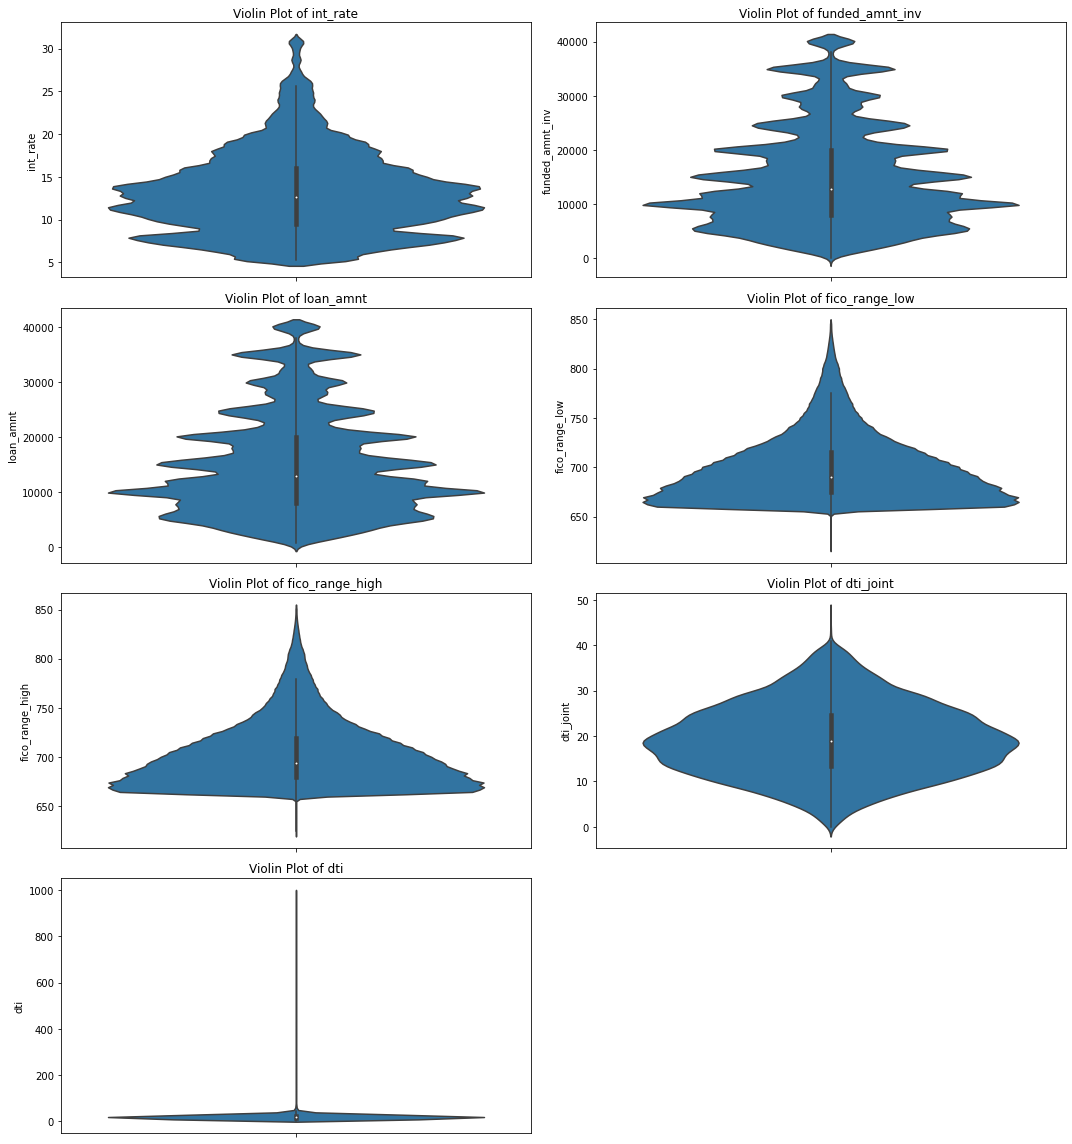

In [27]:
features = ['int_rate','funded_amnt_inv','loan_amnt', 'fico_range_low', 'fico_range_high', 'dti_joint', 'dti']
num_features = len(features)
cols = 2
rows = (num_features + cols - 1) // cols  

fig, axes = plt.subplots(rows, cols, figsize=(15, 4 * rows))  
axes = axes.flatten()  

for i, feature in enumerate(features):
 
    if loan[feature].dtype.kind in 'biufc':  
        sns.violinplot(y=loan[feature], ax=axes[i])
        axes[i].set_title(f'Violin Plot of {feature}')
        axes[i].set_xlabel('')
        axes[i].set_ylabel(feature)
        axes[i].grid(False)
    else:
        axes[i].axis('off') 
        axes[i].set_title(f'Skipped: {feature} (non-numeric)', fontsize=10)


for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

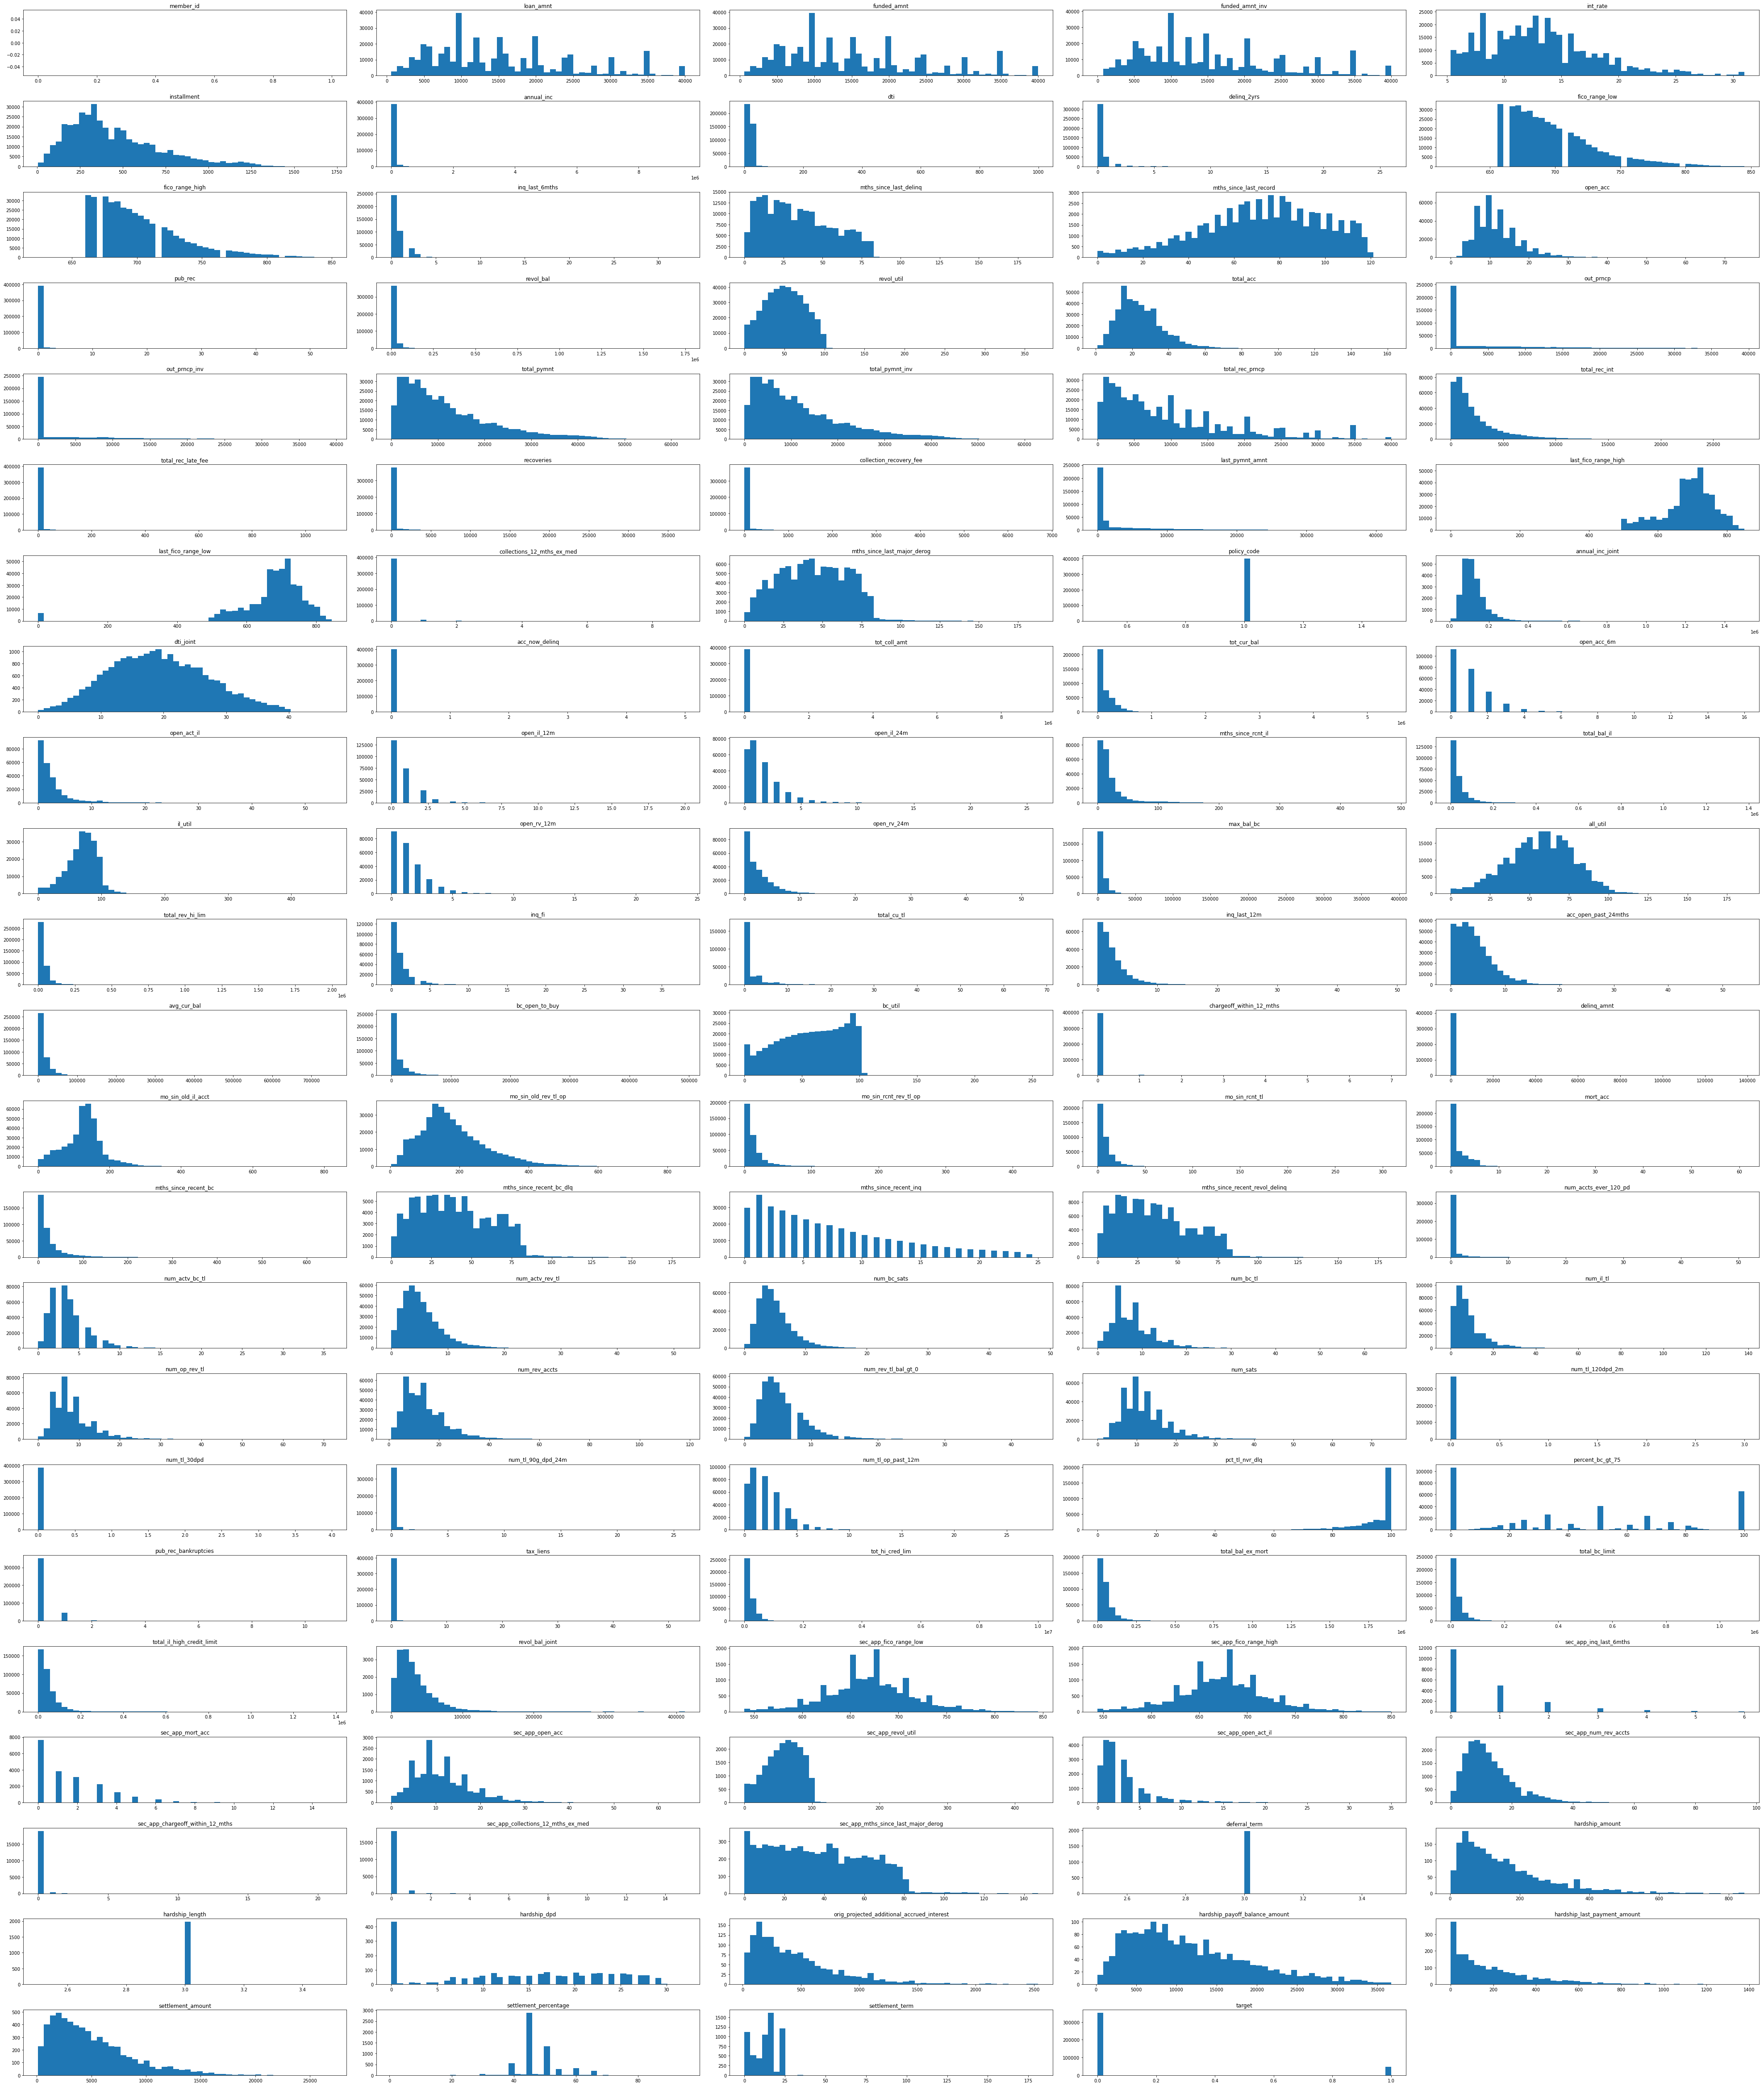

In [28]:
import matplotlib.pyplot as plt

m = 5
loan.hist(figsize=(55, 65), layout=(-1, m), bins=50, grid=False)
plt.tight_layout()
plt.show()

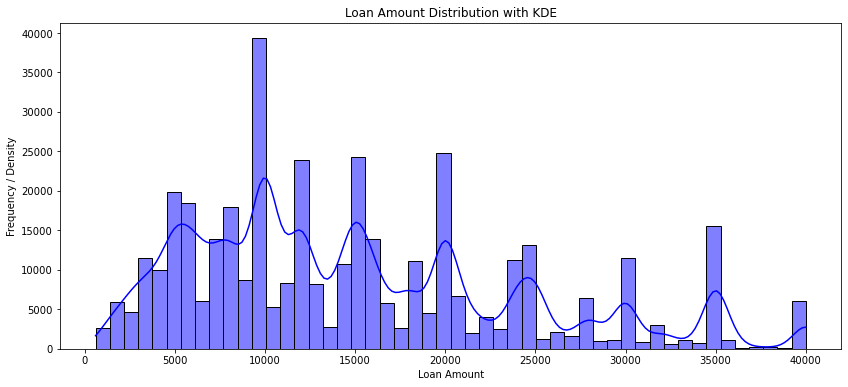

In [29]:
plt.figure(figsize = (14,6))
sns.histplot(x = "loan_amnt", data=loan, color = 'blue', bins = 50, kde=True)
plt.title("Loan Amount Distribution with KDE")
plt.xlabel("Loan Amount")
plt.ylabel("Frequency / Density")
plt.show()

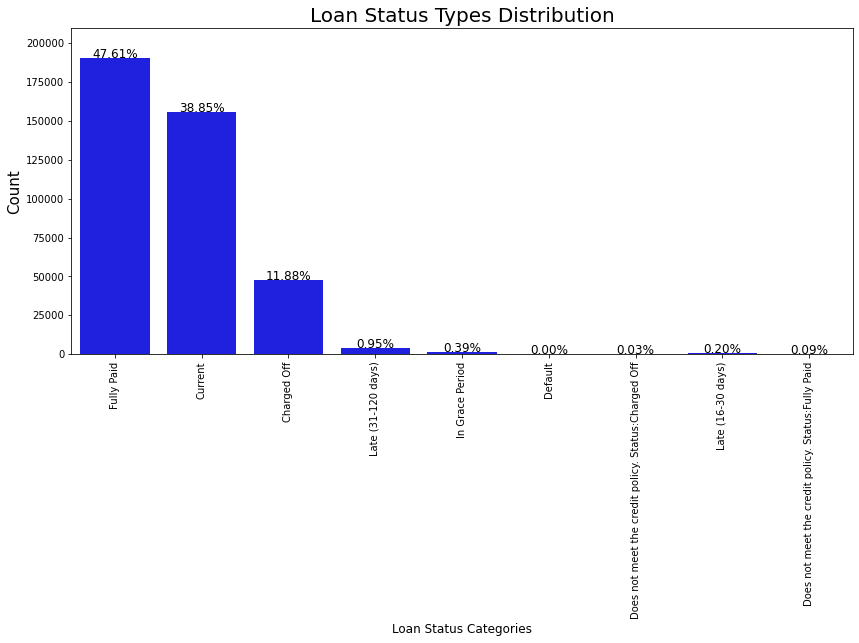

In [30]:
total = len(loan)

plt.figure(figsize = (14,6))

graph = sns.countplot(x="loan_status", data=loan, 
                  color='blue')
graph.set_xticklabels(graph.get_xticklabels(),rotation=90)
graph.set_xlabel("Loan Status Categories", fontsize=12)
graph.set_ylabel("Count", fontsize=15)
graph.set_title("Loan Status Types Distribution", fontsize=20)
sizes=[]
for p in graph.patches:
    height = p.get_height()
    sizes.append(height)
    graph.text(p.get_x()+p.get_width()/2.,
            height + 3,
            '{:1.2f}%'.format(height/total*100),
            ha="center", fontsize=12) 
graph.set_ylim(0, max(sizes) * 1.10)

plt.show()

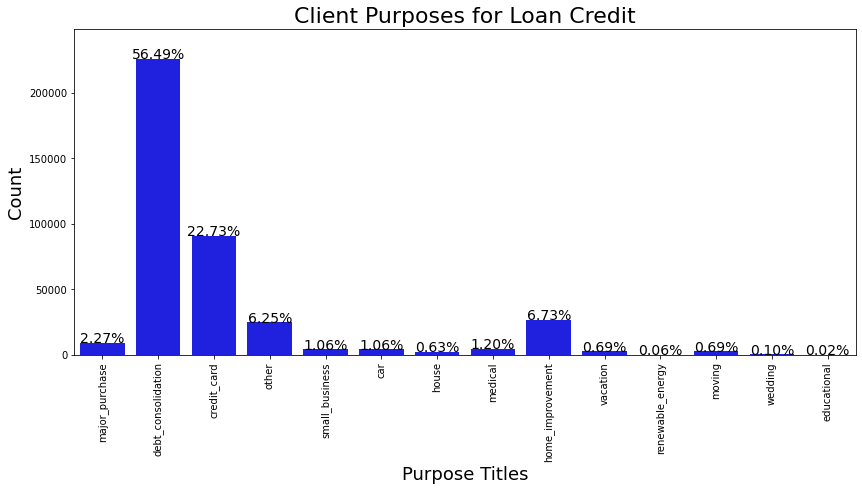

In [31]:
plt.figure(figsize=(14,6))

g = sns.countplot(x='purpose', data=loan, 
                  color='blue')
g.set_title("Client Purposes for Loan Credit", fontsize=22)
g.set_xlabel("Purpose Titles", fontsize=18)
g.set_ylabel('Count', fontsize=18)

sizes=[]

for p in g.patches:
    height = p.get_height()
    sizes.append(height)
    g.text(p.get_x()+p.get_width()/2.,
            height + 3,
            '{:1.2f}%'.format(height/total*100),
            ha="center", fontsize=14) 
    
g.set_ylim(0, max(sizes) * 1.10)
g.set_xticklabels(g.get_xticklabels(),
                  rotation=90)

plt.show()

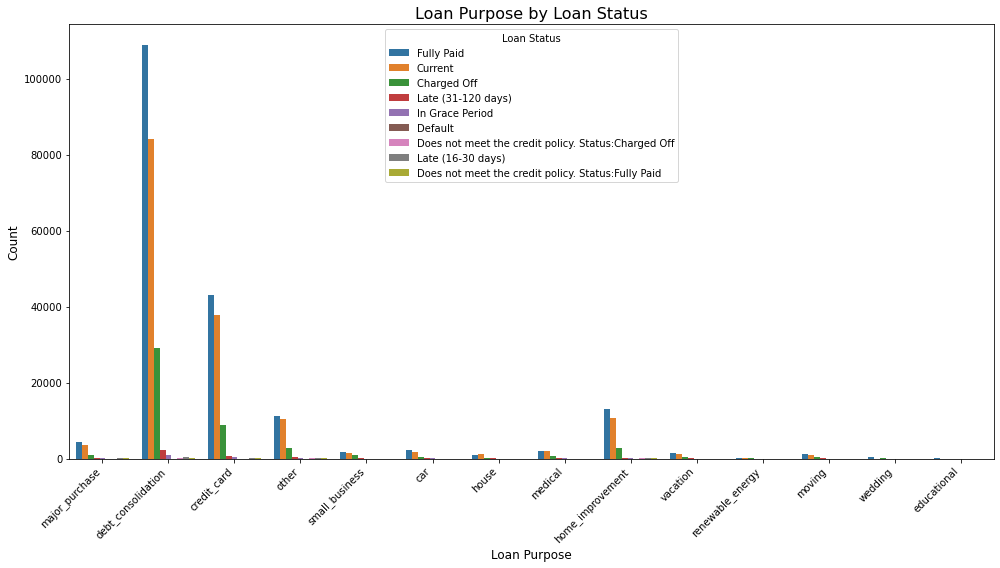

In [32]:

plt.figure(figsize=(14, 8))
sns.countplot(data=loan, x='purpose', hue='loan_status')

plt.xticks(rotation=45, ha='right')
plt.xlabel('Loan Purpose', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.title('Loan Purpose by Loan Status', fontsize=16)
plt.legend(title='Loan Status')
plt.tight_layout()
plt.show()


In [33]:
# Looking more closely at the following features
features = ['loan_amnt', 'term','int_rate', 'sub_grade', 'emp_length', 'home_ownership', 'annual_inc', 'loan_status', 'addr_state', 'dti', 'mths_since_recent_inq', 'revol_util', 'bc_open_to_buy', 'bc_util', 'num_op_rev_tl']

#### Looking for outliers using the Loan Amount Column. 
##### Looking for very "high" values first.

In [34]:
num_percentile = 0.985
high_percentile = loan['loan_amnt'].quantile(num_percentile)
outliers_high_value = loan[(loan['loan_amnt'] > high_percentile)]
print(f"Outliers count above the {num_percentile*100:.2f}th centile: {outliers_high_value['loan_amnt'].count()}")
outliers_high_value.sort_values(by='loan_amnt', ascending=False)

Outliers count above the 98.50th centile: 5987


,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term,target,dataset_type
111,128693358,NaN,40000.0,40000.0,40000.0,36 months,6.72,1229.97,A,A3,...,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN,0,train
271435,97418417,NaN,40000.0,40000.0,40000.0,36 months,12.74,1342.76,C,C1,...,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN,1,test
271946,144809049,NaN,40000.0,40000.0,40000.0,60 months,10.72,864.13,B,B2,...,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN,0,test
271702,137290865,NaN,40000.0,40000.0,40000.0,60 months,16.14,975.71,C,C4,...,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN,0,test
271700,136196883,NaN,40000.0,40000.0,40000.0,60 months,19.92,1057.98,D,D3,...,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN,0,test
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
313821,134143831,NaN,39700.0,39700.0,39700.0,36 months,10.07,1282.32,B,B2,...,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN,0,test
138089,137895188,NaN,39700.0,39700.0,39700.0,36 months,10.08,1282.50,B,B1,...,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN,0,train
145672,140605943,NaN,39700.0,39700.0,39700.0,36 months,11.55,1310.10,B,B4,...,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN,0,train
375734,142977126,NaN,39650.0,39650.0,39650.0,60 months,10.08,844.01,B,B1,...,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN,0,test


### Now dropping high loan amounts

In [35]:
loan = loan.drop(loan[loan['loan_amnt'] > high_percentile].index)
loan['loan_amnt'].sort_values(ascending = False)

333573    39600.0
141356    39600.0
342022    39600.0
93679     39600.0
245408    39600.0
           ...   
21868       600.0
60429         NaN
87614         NaN
217884        NaN
360914        NaN
Name: loan_amnt, Length: 394013, dtype: float64

#### Looking for unusually low values

In [36]:
num_percentile = 0.01
low_percentile = loan['loan_amnt'].quantile(num_percentile)
outliers_low_value = loan[(loan['loan_amnt'] < low_percentile)]
print(f"Outliers count below the {num_percentile*100:.2f}th centile: {outliers_low_value['loan_amnt'].count()}")
outliers_low_value.sort_values(by='loan_amnt', ascending=False)

Outliers count below the 1.00th centile: 2974


,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term,target,dataset_type
30604,125642963,NaN,1475.0,1475.0,1475.0,36 months,9.44,47.21,B,B1,...,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN,0,train
83307,113097805,NaN,1475.0,1475.0,1475.0,36 months,5.32,44.42,A,A1,...,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN,0,train
364647,115174831,NaN,1475.0,1475.0,1475.0,36 months,17.09,52.66,D,D1,...,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN,0,test
228818,125383698,NaN,1475.0,1475.0,1475.0,36 months,7.35,45.79,A,A4,...,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN,0,test
211555,10786285,NaN,1475.0,1475.0,1475.0,36 months,16.24,52.04,C,C5,...,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN,0,test
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
239093,159713,NaN,900.0,900.0,650.0,36 months,10.28,29.16,C,C1,...,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN,1,test
343178,150038,NaN,850.0,850.0,200.0,36 months,14.07,29.08,E,E3,...,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN,0,test
316738,189524,NaN,800.0,800.0,600.0,36 months,13.43,27.13,E,E1,...,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN,0,test
296796,253227,NaN,750.0,750.0,725.0,36 months,12.29,25.02,C,C5,...,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN,0,test


In [37]:
loan = loan.drop(loan[loan['loan_amnt'] < low_percentile].index)
loan['loan_amnt'].sort_values(ascending = True)

52644      1500.0
255603     1500.0
255707     1500.0
255781     1500.0
255877     1500.0
           ...   
93679     39600.0
60429         NaN
87614         NaN
217884        NaN
360914        NaN
Name: loan_amnt, Length: 391039, dtype: float64

In [38]:
loan_amount = loan['loan_amnt'].dropna()
mean_amount = loan_amount.mean()
median_amount = loan_amount.median()

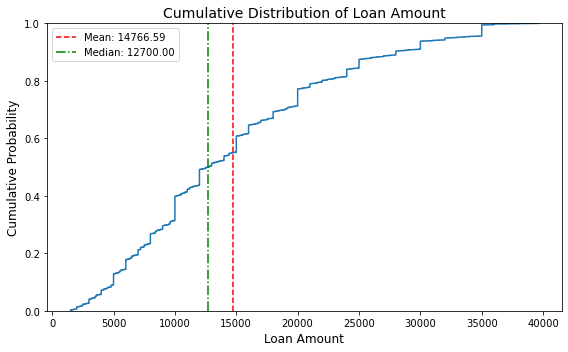

In [39]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))
sns.ecdfplot(data=loan, x='loan_amnt') #,hue='target')
plt.axvline(mean_amount, color='red', linestyle='--', label=f'Mean: {mean_amount:.2f}')
plt.axvline(median_amount, color='green', linestyle='-.', label=f'Median: {median_amount:.2f}')
plt.xlabel('Loan Amount', fontsize=12)
plt.ylabel('Cumulative Probability', fontsize=12)
plt.title('Cumulative Distribution of Loan Amount', fontsize=14)
plt.legend()
plt.grid(False)
plt.tight_layout()
plt.show()


In [40]:
interest_rates = loan['int_rate'].dropna()
mean_rate = interest_rates.mean()
median_rate = interest_rates.median()

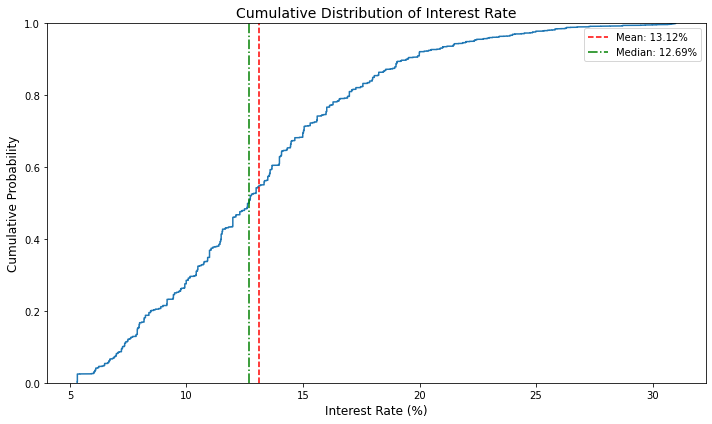

In [41]:
plt.figure(figsize=(10, 6))
sns.ecdfplot(data=interest_rates)

plt.axvline(mean_rate, color='red', linestyle='--', label=f'Mean: {mean_rate:.2f}%')
plt.axvline(median_rate, color='green', linestyle='-.', label=f'Median: {median_rate:.2f}%')

plt.xlabel('Interest Rate (%)', fontsize=12)
plt.ylabel('Cumulative Probability', fontsize=12)
plt.title('Cumulative Distribution of Interest Rate', fontsize=14)
plt.legend()
plt.grid(False)
plt.tight_layout()
plt.show()


## Addressing outliers in the Innual Income feature

In [42]:
### There are also  outliers in the annual_inc columns that I should get rid off
quarter_low = loan["annual_inc"].quantile(0.01)  
quarter_high = loan["annual_inc"].quantile(0.99) 
loans_extreme = loan[(loan["annual_inc"] < quarter_high) & (loan["annual_inc"] > quarter_low)]  
num_cols = ['annual_inc']

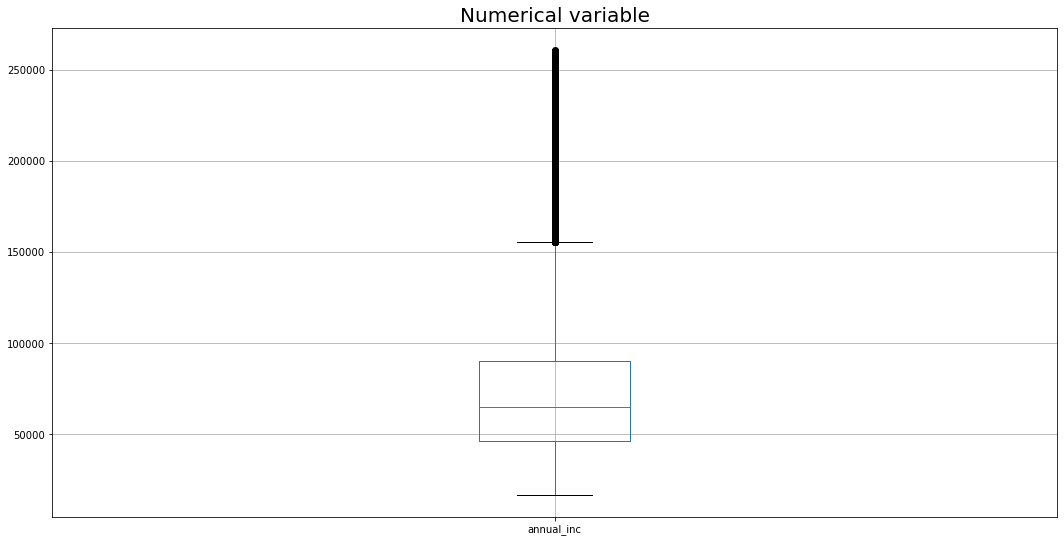

In [43]:
plt.figure(figsize=(18,9))  
loans_extreme[num_cols].boxplot()  
plt.title("Numerical variable", fontsize=20)  
plt.show()


In [44]:
num_percentile = 0.975
high_percentile = loan['annual_inc'].quantile(num_percentile)
loan = loan[loan['annual_inc'] <= high_percentile]
loan['annual_inc'].sort_values(ascending = True)

312885         0.0
269198         0.0
151919         0.0
167784         0.0
326250         0.0
            ...   
318204    200000.0
210508    200000.0
13580     200000.0
121124    200000.0
198927    200000.0
Name: annual_inc, Length: 382458, dtype: float64

In [45]:
num_percentile = 0.01
low_percentile = loan['annual_inc'].quantile(num_percentile)
loan = loan[loan['annual_inc'] >= low_percentile]
loan['annual_inc'].sort_values(ascending = False)

266330    200000.00
49583     200000.00
392081    200000.00
203874    200000.00
91243     200000.00
            ...    
345534     16656.00
238777     16656.00
126075     16650.00
351133     16650.00
348207     16642.08
Name: annual_inc, Length: 378633, dtype: float64

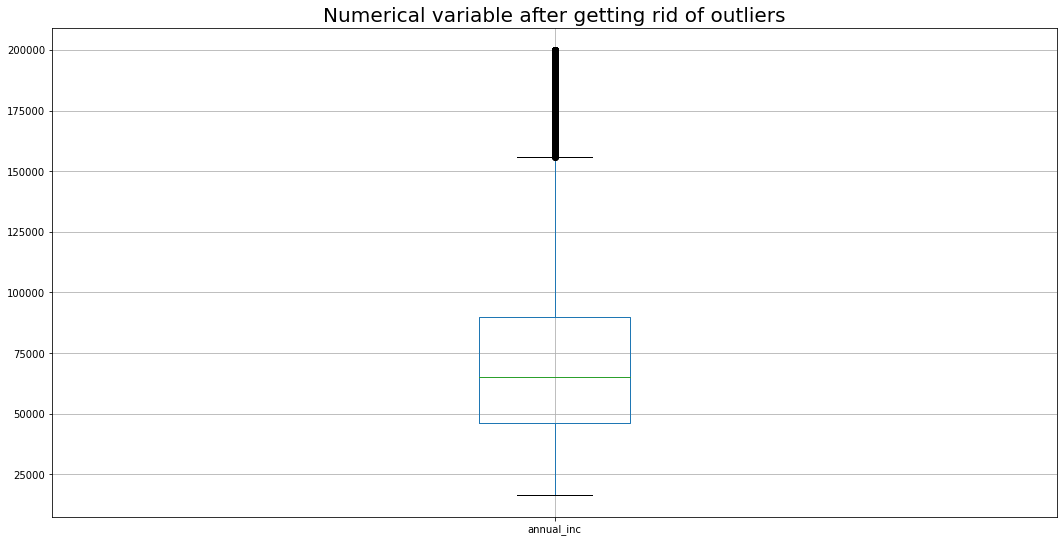

In [46]:
plt.figure(figsize=(18,9))  
loan[num_cols].boxplot()  
plt.title("Numerical variable after getting rid of outliers", fontsize=20)  
plt.show()

In [47]:
int_default = pd.crosstab(loan['int_rate'], loan['target'])
int_default['percent_default'] = int_default[1]/(int_default[0]+int_default[1])
int_default

target,0,1,percent_default
int_rate,,,
5.31,1322,4,0.003017
5.32,7475,151,0.019801
5.42,122,1,0.008130
5.79,67,2,0.028986
5.93,285,7,0.023973
...,...,...,...
30.79,201,60,0.229885
30.84,88,48,0.352941
30.89,89,35,0.282258


## Looking at the distribution of defaut rate by credit grade

In [48]:
ct = pd.crosstab(loan['grade'], loan['target'])
ct['percent_default'] = ct[1] / (ct[1] + ct[0])
ct

target,0,1,percent_default
grade,,,
A,68730,2434,0.034203
B,102090,8964,0.080717
C,94908,14574,0.133118
D,44558,10421,0.189545
E,16564,6277,0.274813
F,4597,2452,0.347851
G,1301,763,0.369671


In [49]:
ct_reset = ct.reset_index()
ct_reset

target,grade,0,1,percent_default
0,A,68730,2434,0.034203
1,B,102090,8964,0.080717
2,C,94908,14574,0.133118
3,D,44558,10421,0.189545
4,E,16564,6277,0.274813
5,F,4597,2452,0.347851
6,G,1301,763,0.369671


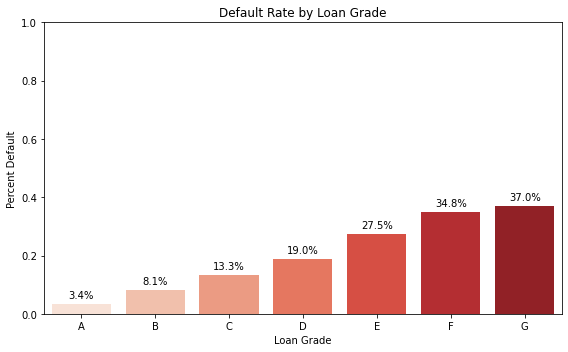

In [50]:
plt.figure(figsize=(8,5))
ax = sns.barplot(data=ct_reset, x='grade', y='percent_default', palette='Reds')


plt.title('Default Rate by Loan Grade')
plt.ylabel('Percent Default')
plt.xlabel('Loan Grade')
plt.ylim(0, 1)  # since percent_default is between 0 and 1

for p in ax.patches:
    height = p.get_height()
    ax.text(
        x=p.get_x() + p.get_width() / 2,  
        y=height + 0.02,                  
        s=f'{height * 100:.1f}%',         
        ha='center'                      
    )

plt.tight_layout()
plt.show()

## Exploring Multicollinerarity

### Assessing Multicollinearity using the Correlation Matrix

In [51]:
indpt_var = loan.drop("target", axis=1)
collinear_features = indpt_var.corr()[indpt_var.corr()>0.8]
collinear_features

,member_id,loan_amnt,funded_amnt,funded_amnt_inv,int_rate,installment,annual_inc,dti,delinq_2yrs,fico_range_low,...,deferral_term,hardship_amount,hardship_length,hardship_dpd,orig_projected_additional_accrued_interest,hardship_payoff_balance_amount,hardship_last_payment_amount,settlement_amount,settlement_percentage,settlement_term
member_id,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan_amnt,NaN,1.000000,0.999688,0.998952,NaN,0.942771,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,0.852165,NaN,NaN,NaN,NaN
funded_amnt,NaN,0.999688,1.000000,0.999325,NaN,0.943188,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,0.852165,NaN,NaN,NaN,NaN
funded_amnt_inv,NaN,0.998952,0.999325,1.000000,NaN,0.942315,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,0.852159,NaN,NaN,NaN,NaN
int_rate,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
hardship_payoff_balance_amount,NaN,0.852165,0.852165,0.852159,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,0.888429,NaN,NaN,0.886274,1.000000,NaN,0.94811,NaN,NaN
hardship_last_payment_amount,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN
settlement_amount,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,0.862014,NaN,NaN,NaN,0.948110,NaN,1.00000,NaN,NaN
settlement_percentage,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN


In [52]:
collinear_features.loc['loan_amnt'][collinear_features.loc['loan_amnt'].notnull()]


loan_amnt                         1.000000
funded_amnt                       0.999688
funded_amnt_inv                   0.998952
installment                       0.942771
hardship_payoff_balance_amount    0.852165
Name: loan_amnt, dtype: float64

In [53]:
for feature in collinear_features.index:
    non_null_corrs = collinear_features.loc[feature].dropna()
    print(f"\n - {feature.upper()} (correlated with {len(non_null_corrs)} features):")
    print(non_null_corrs.to_string())


 - MEMBER_ID (correlated with 0 features):
Series([], )

 - LOAN_AMNT (correlated with 5 features):
loan_amnt                         1.000000
funded_amnt                       0.999688
funded_amnt_inv                   0.998952
installment                       0.942771
hardship_payoff_balance_amount    0.852165

 - FUNDED_AMNT (correlated with 5 features):
loan_amnt                         0.999688
funded_amnt                       1.000000
funded_amnt_inv                   0.999325
installment                       0.943188
hardship_payoff_balance_amount    0.852165

 - FUNDED_AMNT_INV (correlated with 5 features):
loan_amnt                         0.998952
funded_amnt                       0.999325
funded_amnt_inv                   1.000000
installment                       0.942315
hardship_payoff_balance_amount    0.852159

 - INT_RATE (correlated with 1 features):
int_rate    1.0

 - INSTALLMENT (correlated with 4 features):
loan_amnt          0.942771
funded_amnt        0.9431

### Dropping features that are too highly correlated (threshold: 0.8)

In [54]:
def drop_high_corr(df, threshold=0.8):
    corr_matrix = df.corr().abs()
    upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    to_drop = [column for column in upper.columns if any(upper[column] > threshold)]
    return df.drop(columns=to_drop)

df_reduced = drop_high_corr(loan)

In [55]:
df_reduced.head()

,id,member_id,loan_amnt,term,int_rate,grade,sub_grade,emp_title,emp_length,home_ownership,...,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_percentage,settlement_term,target,dataset_type
0,1006259,NaN,2500.0,36 months,11.71,B,B3,NaN,2 years,OWN,...,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,0,train
1,50303671,NaN,7425.0,36 months,18.55,E,E2,New Patient Check in,1 year,MORTGAGE,...,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,0,train
2,30485774,NaN,15700.0,36 months,11.67,B,B4,RN,10+ years,MORTGAGE,...,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,0,train
3,29183992,NaN,8450.0,36 months,18.99,E,E1,Assistant customer service manager,1 year,RENT,...,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,0,train
4,62644235,NaN,15000.0,36 months,7.89,A,A5,Officer,< 1 year,OWN,...,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,0,train


In [56]:
loan = df_reduced.copy()


### List of columns I dropped for the purpose of using Linear models based on:
### - the Lending Club dataset data dictionary, and 
### - the above Multicollinearity analysis.
### - Post Loan Information that could create information leakage


### - ID / Administrative Fields

- id: unique loan ID, meaningless for prediction
- member_id: internal customer ID, also unique
- url Link: to loan listing, this is metadata 
- policy_code: constant (always 1)
- application_type: often not predictive (joint vs individual)
- disbursement method (payment method used by investor to provide the loan: credit card, cash...)

### - Text Fields

- emp_title: essy & hard to use without NLP
- desc: User-submitted loan description
- title: Loan title — this information isn't important  (there is already a purpose column)

### - Collinear & Redundant Information (all these are highly correlated to "loan_amnt")

- funded_amnt                       
- funded_amnt_inv                  
- installment                       
- hardship_payoff_balance_amount    
- settlement_amount  
- FICO_scores    
- grade (however I will preserve the sub-grade feature as it carries more granular information than Grade)
- zip_code as there are other features conveying geographic data such as 'state'.

### - Column that was encoded to serve as the new Target Feature:\
- loan_status

### - Post-loan information which could represent a form of information leakage, my aim here is to predict loan default before default is known. Some of the below column column are cofounding variables of default as provide information that one wouldn't have ahead of a customer defaulting (in particular at the time the loan was issued)
- total_pymnt: total paid — outcome data
- total_pymnt_inv: Investor perspective — post-outcome
- total_rec_prncp: Total principal received
- total_rec_int: Total interest received
- total_rec_late_fee: Outcome-only
- recoveries: Amount recovered after charge-off
- collection_recovery_fee: Fees recovered — not known at origination
- last_pymnt_d: Last payment date — post-issue
- last_pymnt_amnt: Amount of last payment
- next_pymnt_d: Next scheduled payment — dynamic
- last_credit_pull_d: Date of last credit report pull — post-loan
- hardship_flag: flag indicating post-loan hardship event
- debt_settlement_flag: indicates whether loan ended in debt settlement — outcome data

- out_prncp: remaining principal — only known post-issue
- out_prncp_inv: rame, investor view



In [57]:
columns_to_drop = [
    'id',                    # Unique loan ID, not predictive
    'member_id',             # Internal customer ID, unique
    'url',                   # Link to loan listing, metadata
    'policy_code',           # Constant value (e.g. always 1)
    'application_type',      # Often not predictive
    'disbursement_method',    # Not useful for model
    'initial_list_status',   # Not useful for modelling credit risk - refers to the status of the loan at the time it was listed on the platform 
                             #(i.ewhether it was listed as a whole loan or a fractional loan.

    # Text fields
    'emp_title',             # Free text, messy
    'desc',                  # User-submitted description
    'title',                 # Redundant with 'purpose'
    
    # Collinear and redundant features
    'funded_amnt',                      
    'funded_amnt_inv',                 
    'installment',                      
    'hardship_payoff_balance_amount',   
    'settlement_amount',  
    'FICO_scores',   
    'grade',
    'zip_code',

    # the target feature corresponds to the encoded loan_status feature
    'loan_status',

    # Post-loan outcome variables
    'total_pymnt',
    'total_pymnt_inv',
    'total_rec_prncp',
    'total_rec_int',
    'total_rec_late_fee',
    'recoveries',
    'collection_recovery_fee',
    'last_pymnt_d',
    'last_pymnt_amnt',
    'next_pymnt_d',
    'last_credit_pull_d',
    'hardship_flag',
    'debt_settlement_flag',


    # Remaining principal
    'out_prncp',
    'out_prncp_inv'
]


### Dropping features with "too many" null values

In [58]:
#Identifying features with a lot of missing values.
missing_percent = ((loan.isnull().sum() / loan.shape[0]) * 100).sort_values(ascending=False)
missing_percent = missing_percent.round(2).astype(str) + '%'
print(missing_percent)

member_id              100.0%
hardship_start_date     99.5%
hardship_dpd            99.5%
hardship_type           99.5%
hardship_reason         99.5%
                        ...  
out_prncp                0.0%
initial_list_status      0.0%
revol_bal                0.0%
fico_range_low           0.0%
id                       0.0%
Length: 124, dtype: object


In [59]:

def removing_highnull_features(df,percent):
    max_nulls = df.shape[0]*percent   

    columns = df.columns.to_list()
    col_to_drop = []

    for col in columns:
        if df[col].isnull().sum()> max_nulls:
            col_to_drop.append(col)
        
    return df.drop(columns=col_to_drop)

#We will drop features with 65% or more null values
df_nonull = removing_highnull_features(loan,0.65)
loan_clean = df_nonull
loan_clean.info(verbose=True)

<class 'pandas.core.frame.DataFrame'>
Int64Index: 378633 entries, 0 to 399999
Data columns (total 87 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   id                          378633 non-null  object 
 1   loan_amnt                   378633 non-null  float64
 2   term                        378633 non-null  object 
 3   int_rate                    378633 non-null  float64
 4   grade                       378633 non-null  object 
 5   sub_grade                   378633 non-null  object 
 6   emp_title                   352313 non-null  object 
 7   emp_length                  355524 non-null  object 
 8   home_ownership              378633 non-null  object 
 9   annual_inc                  378633 non-null  float64
 10  verification_status         378633 non-null  object 
 11  issue_d                     378633 non-null  object 
 12  loan_status                 378633 non-null  object 
 13  pymnt_plan    

In [60]:
remaining_null = loan_clean.isnull().mean() * 100
remaining_null.sort_values(ascending=False)

next_pymnt_d              60.311700
mths_since_last_delinq    51.138702
il_util                   47.729332
mths_since_rcnt_il        40.995106
all_util                  39.140804
                            ...    
out_prncp                  0.000000
initial_list_status        0.000000
revol_bal                  0.000000
fico_range_low             0.000000
id                         0.000000
Length: 87, dtype: float64

In [61]:
loan_final = loan_clean.drop(columns=[col for col in columns_to_drop if col in loan_clean.columns])
loan_final.columns

Index(['loan_amnt', 'term', 'int_rate', 'sub_grade', 'emp_length',
       'home_ownership', 'annual_inc', 'verification_status', 'issue_d',
       'pymnt_plan', 'purpose', 'addr_state', 'dti', 'delinq_2yrs',
       'earliest_cr_line', 'fico_range_low', 'inq_last_6mths',
       'mths_since_last_delinq', 'open_acc', 'pub_rec', 'revol_bal',
       'revol_util', 'total_acc', 'last_fico_range_high',
       'collections_12_mths_ex_med', 'acc_now_delinq', 'tot_coll_amt',
       'tot_cur_bal', 'open_acc_6m', 'open_act_il', 'open_il_12m',
       'open_il_24m', 'mths_since_rcnt_il', 'total_bal_il', 'il_util',
       'open_rv_12m', 'open_rv_24m', 'max_bal_bc', 'all_util',
       'total_rev_hi_lim', 'inq_fi', 'total_cu_tl', 'inq_last_12m',
       'bc_open_to_buy', 'chargeoff_within_12_mths', 'delinq_amnt',
       'mo_sin_old_il_acct', 'mo_sin_old_rev_tl_op', 'mo_sin_rcnt_rev_tl_op',
       'mo_sin_rcnt_tl', 'mort_acc', 'mths_since_recent_bc',
       'mths_since_recent_inq', 'num_accts_ever_120_pd'

In [62]:
loan_final.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 378633 entries, 0 to 399999
Data columns (total 65 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   loan_amnt                   378633 non-null  float64
 1   term                        378633 non-null  object 
 2   int_rate                    378633 non-null  float64
 3   sub_grade                   378633 non-null  object 
 4   emp_length                  355524 non-null  object 
 5   home_ownership              378633 non-null  object 
 6   annual_inc                  378633 non-null  float64
 7   verification_status         378633 non-null  object 
 8   issue_d                     378633 non-null  object 
 9   pymnt_plan                  378633 non-null  object 
 10  purpose                     378633 non-null  object 
 11  addr_state                  378633 non-null  object 
 12  dti                         378633 non-null  float64
 13  delinq_2yrs   

### Now I am going to encode categorical columns

In [63]:
loan_final.select_dtypes(include=[object])

,term,sub_grade,emp_length,home_ownership,verification_status,issue_d,pymnt_plan,purpose,addr_state,earliest_cr_line,dataset_type
0,36 months,B3,2 years,OWN,Source Verified,Nov-2011,n,major_purchase,FL,Nov-2007,train
1,36 months,E2,1 year,MORTGAGE,Source Verified,Jun-2015,n,debt_consolidation,FL,Jul-2005,train
2,36 months,B4,10+ years,MORTGAGE,Source Verified,Oct-2014,n,debt_consolidation,DE,Nov-1998,train
3,36 months,E1,1 year,RENT,Not Verified,Oct-2014,n,debt_consolidation,MD,Aug-2011,train
4,36 months,A5,< 1 year,OWN,Not Verified,Oct-2015,n,debt_consolidation,MD,Oct-2005,train
...,...,...,...,...,...,...,...,...,...,...,...
399995,36 months,C3,4 years,MORTGAGE,Source Verified,Mar-2016,n,renewable_energy,TX,Jun-1998,test
399996,36 months,A5,10+ years,MORTGAGE,Not Verified,Oct-2012,n,debt_consolidation,TX,Jan-1995,test
399997,60 months,C3,3 years,MORTGAGE,Verified,Jul-2018,n,credit_card,TX,Jun-2001,test
399998,36 months,B5,10+ years,RENT,Source Verified,Nov-2017,n,debt_consolidation,NY,Nov-2002,test


#### Reviewing the last potentially irrelevant object-type columns before encoding them.

In [64]:
# Looking at the payment_plan feature:

print(loan_final['pymnt_plan'].value_counts())

n    378519
y       114
Name: pymnt_plan, dtype: int64


In [65]:
# Given the few "y" values, this feature is irrelevant, let's drop it.
loan_final = loan_final.drop('pymnt_plan', axis=1)
loan_final.select_dtypes(include=[object])

,term,sub_grade,emp_length,home_ownership,verification_status,issue_d,purpose,addr_state,earliest_cr_line,dataset_type
0,36 months,B3,2 years,OWN,Source Verified,Nov-2011,major_purchase,FL,Nov-2007,train
1,36 months,E2,1 year,MORTGAGE,Source Verified,Jun-2015,debt_consolidation,FL,Jul-2005,train
2,36 months,B4,10+ years,MORTGAGE,Source Verified,Oct-2014,debt_consolidation,DE,Nov-1998,train
3,36 months,E1,1 year,RENT,Not Verified,Oct-2014,debt_consolidation,MD,Aug-2011,train
4,36 months,A5,< 1 year,OWN,Not Verified,Oct-2015,debt_consolidation,MD,Oct-2005,train
...,...,...,...,...,...,...,...,...,...,...
399995,36 months,C3,4 years,MORTGAGE,Source Verified,Mar-2016,renewable_energy,TX,Jun-1998,test
399996,36 months,A5,10+ years,MORTGAGE,Not Verified,Oct-2012,debt_consolidation,TX,Jan-1995,test
399997,60 months,C3,3 years,MORTGAGE,Verified,Jul-2018,credit_card,TX,Jun-2001,test
399998,36 months,B5,10+ years,RENT,Source Verified,Nov-2017,debt_consolidation,NY,Nov-2002,test


### Let's now create a new feature, "credit-history_years' using both features: earliest_cr_line and 'issue_d'. This feature will be interesting as it will provide us an idea of the borrower's cedit history.

In [66]:
import pandas as pd

def transform_earliest_cr_line(df, cr_col='earliest_cr_line', issue_col='issue_d'):
   
    df[cr_col] = pd.to_datetime(df[cr_col], format='%b-%Y', errors='coerce')
    df[issue_col] = pd.to_datetime(df[issue_col], format='%b-%Y', errors='coerce')

    # Calculating credit history in years relative to issue date
    df['credit_history_years'] = df[issue_col].dt.year - df[cr_col].dt.year
    df = df.drop([cr_col, issue_col], axis = 1)

    return df


In [67]:
loan_final = transform_earliest_cr_line(loan_final)

In [68]:
loan_final[['credit_history_years']].head()

,credit_history_years
0,4.0
1,10.0
2,16.0
3,3.0
4,10.0


### Now, I am converting the 'term' columns to integers.

In [69]:
loan_final['term'].unique()

array([' 36 months', ' 60 months'], dtype=object)

In [70]:
def transform_term (df, term_col='term'):
    loan_final[term_col] = loan_final[term_col].str.strip().replace({'36 months': 36, '60 months': 60})
    return df

In [71]:
loan_final = transform_term(loan_final)
loan_final[['term']].head()

,term
0,36
1,36
2,36
3,36
4,36


In [72]:
loan_final[loan_final['term'].isnull()]

,loan_amnt,term,int_rate,sub_grade,emp_length,home_ownership,annual_inc,verification_status,purpose,addr_state,...,num_il_tl,num_tl_120dpd_2m,num_tl_30dpd,num_tl_90g_dpd_24m,pct_tl_nvr_dlq,pub_rec_bankruptcies,tax_liens,target,dataset_type,credit_history_years


In [73]:
loan_final['term'].isnull().sum()

0

### Manually encoding the following ordinal features: 'sub_grade_col' and 'emp_length'. I manually created an integer "hierarchy" in order to preserve the 'order' of these variables

In [74]:
def manually_encode_ordinal(df, sub_grade_col='sub_grade', emp_length_col='emp_length'):
    cleaner_app_type = {
    sub_grade_col: {"A1": 1.0, "A2": 2.0, "A3": 3.0, "A4": 4.0, "A5": 5.0, "B1": 11.0, "B2": 12.0, "B3": 13.0, "B4": 14.0, "B5": 15.0, "C1": 21.0, "C2": 22.0, "C3": 23.0, "C4": 24.0, "C5": 25.0, "D1": 31.0, "D2": 32.0, "D3": 33.0, "D4": 34.0, "D5": 35.0, "E1": 41.0, "E2": 42.0, "E3": 43.0, "E4": 44.0, "E5": 45.0, "F1": 51.0, "F2": 52.0, "F3": 53.0, "F4": 54.0, "F5": 55.0, "G1": 61.0, "G2": 62.0, "G3": 63.0, "G4": 64.0, "G5": 65.0, },  
    emp_length_col: {"< 1 year": 0.0, '1 year': 1.0, '2 years': 2.0, '3 years': 3.0, '4 years': 4.0, '5 years': 5.0, '6 years': 6.0, '7 years': 7.0, '8 years': 8.0, '9 years': 9.0, '10+ years': 10.0 }  }  
    

    df = df.replace(cleaner_app_type)
    return df

In [75]:

loan_final = manually_encode_ordinal(loan_final)

In [76]:
loan_final[['sub_grade','emp_length']]

,sub_grade,emp_length
0,13.0,2.0
1,42.0,1.0
2,14.0,10.0
3,41.0,1.0
4,5.0,0.0
...,...,...
399995,23.0,4.0
399996,5.0,10.0
399997,23.0,3.0
399998,15.0,10.0


In [77]:
loan_final.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 378633 entries, 0 to 399999
Data columns (total 63 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   loan_amnt                   378633 non-null  float64
 1   term                        378633 non-null  int64  
 2   int_rate                    378633 non-null  float64
 3   sub_grade                   378633 non-null  float64
 4   emp_length                  355524 non-null  float64
 5   home_ownership              378633 non-null  object 
 6   annual_inc                  378633 non-null  float64
 7   verification_status         378633 non-null  object 
 8   purpose                     378633 non-null  object 
 9   addr_state                  378633 non-null  object 
 10  dti                         378633 non-null  float64
 11  delinq_2yrs                 378630 non-null  float64
 12  fico_range_low              378633 non-null  float64
 13  inq_last_6mths

### Performing "One Hot Encoding" for the following columns:
- home_ownership,
- verification_status,	
- purpose
- addr_state.


In [78]:
loan_final.select_dtypes(object)

,home_ownership,verification_status,purpose,addr_state,dataset_type
0,OWN,Source Verified,major_purchase,FL,train
1,MORTGAGE,Source Verified,debt_consolidation,FL,train
2,MORTGAGE,Source Verified,debt_consolidation,DE,train
3,RENT,Not Verified,debt_consolidation,MD,train
4,OWN,Not Verified,debt_consolidation,MD,train
...,...,...,...,...,...
399995,MORTGAGE,Source Verified,renewable_energy,TX,test
399996,MORTGAGE,Not Verified,debt_consolidation,TX,test
399997,MORTGAGE,Verified,credit_card,TX,test
399998,RENT,Source Verified,debt_consolidation,NY,test


In [79]:
cat_columns = loan_final.select_dtypes(object).columns

loans_final_encoded = pd.get_dummies(loan_final, prefix_sep="__", columns=cat_columns)
loans_final_encoded

,loan_amnt,term,int_rate,sub_grade,emp_length,annual_inc,dti,delinq_2yrs,fico_range_low,inq_last_6mths,...,addr_state__TX,addr_state__UT,addr_state__VA,addr_state__VT,addr_state__WA,addr_state__WI,addr_state__WV,addr_state__WY,dataset_type__test,dataset_type__train
0,2500.0,36,11.71,13.0,2.0,27600.0,1.48,0.0,740.0,0.0,...,0,0,0,0,0,0,0,0,0,1
1,7425.0,36,18.55,42.0,1.0,26000.0,14.27,0.0,660.0,1.0,...,0,0,0,0,0,0,0,0,0,1
2,15700.0,36,11.67,14.0,10.0,68000.0,11.05,0.0,675.0,2.0,...,0,0,0,0,0,0,0,0,0,1
3,8450.0,36,18.99,41.0,1.0,25000.0,11.23,0.0,690.0,1.0,...,0,0,0,0,0,0,0,0,0,1
4,15000.0,36,7.89,5.0,0.0,40000.0,19.29,0.0,720.0,0.0,...,0,0,0,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
399995,12000.0,36,13.67,23.0,4.0,61500.0,34.87,0.0,685.0,0.0,...,1,0,0,0,0,0,0,0,1,0
399996,9600.0,36,8.90,5.0,10.0,41000.0,10.24,0.0,715.0,0.0,...,1,0,0,0,0,0,0,0,1,0
399997,35000.0,60,15.02,23.0,3.0,64000.0,33.26,0.0,685.0,0.0,...,1,0,0,0,0,0,0,0,1,0
399998,8000.0,36,11.99,15.0,10.0,42925.0,22.81,0.0,660.0,2.0,...,0,0,0,0,0,0,0,0,1,0


### Looking again at the distribution of the Numerical (type float) features still present in the Dataset

In [80]:
loans_final_encoded = loans_final_encoded.dropna()

In [81]:
float_columns = loans_final_encoded.select_dtypes(float).columns.to_list()
loans_float = loans_final_encoded[float_columns]

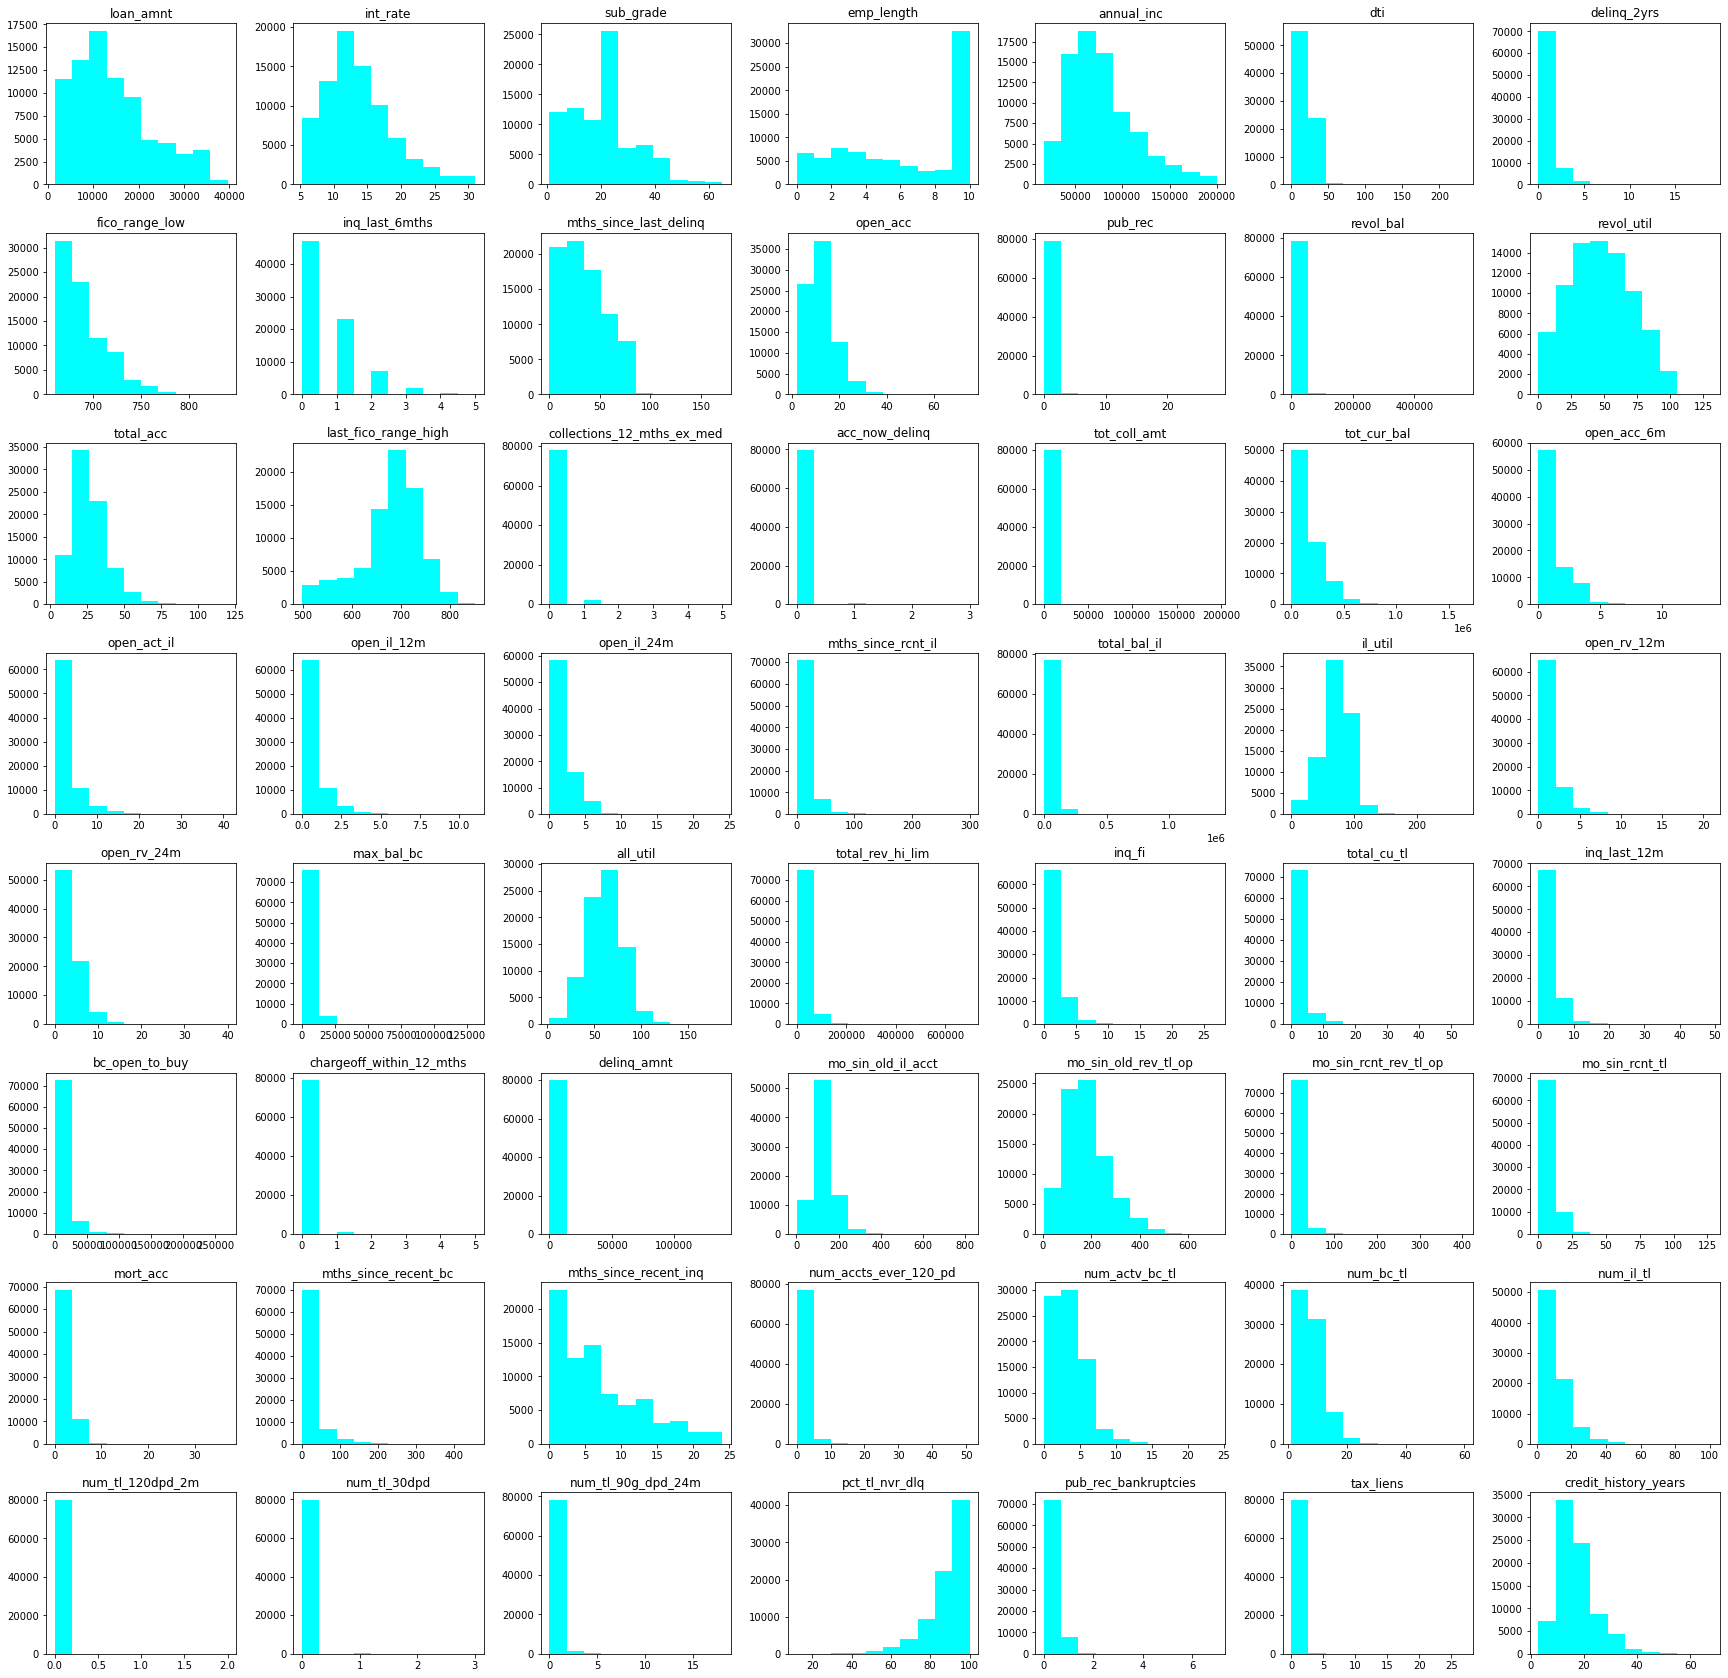

In [82]:
loans_float.hist(bins = 10, figsize = (30,30), color = 'cyan', grid=False)
None

## WEEK 8: Implementing K-Nearest Neighbors on the Cleaned Dataset


In [83]:
X = loans_final_encoded.drop('target', axis = 1)
y = loans_final_encoded['target']

In [84]:
X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.33, random_state=42)

In [85]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from scipy.stats import randint

### As indicated in the course material, K-Nearest Neighbors works more efficiently if the features are standardized, as this removes differences in scale between features (or covariates), ensuring that no single feature disproportionately influences the distance calculations. Thus, I created a small Pipeline that uses the StandardScaler transformer first.

In [86]:

pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier())
])

### Given the four types of distances available for K-Nearest Neighbors, I decided to perform a RandomizedSearchCV to explore different distance metrics, the number of neighbors, and the weighting strategy (i.e whether all neighbors are treated equally or if closer neighbors should have more influence), in order to identify the combination that maximizes performance.

In [ ]:
# Parameters
param_dist = {
    'knn__n_neighbors': [2, 5, 10],
    'knn__metric': ['euclidean', 'manhattan', 'minkowski', 'cosine'],
    'knn__weights': ['uniform', 'distance']
}

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


random_search = RandomizedSearchCV(
    estimator=pipe,
    param_distributions=param_dist,
    n_iter=20,  # number of random combinations to try
    cv=cv,
    scoring='recall',
    random_state=42,
    n_jobs=-1
)


In [ ]:
random_search.fit(X_train, y_train)

# Best parameters and output score
print("Best parameters:", random_search.best_params_)
print("Best CV recall (macro):", random_search.best_score_)

Best parameters: {'knn__weights': 'distance', 'knn__n_neighbors': 2, 'knn__metric': 'minkowski'}
Best CV recall (macro): 0.5830030538551652


In [ ]:
from sklearn.metrics import classification_report
best_knn = random_search.best_estimator_

y_pred = best_knn.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.92      0.95      0.93     23763
           1       0.32      0.20      0.25      2636

    accuracy                           0.88     26399
   macro avg       0.62      0.58      0.59     26399
weighted avg       0.86      0.88      0.86     26399



## Implementing Gradient Boost on the Cleaned Dataset

In [98]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import classification_report
from scipy.stats import uniform, randint

## RandomizedSearchCV for GradientBoostingClassifier

### Hyperparameter sweep:
#### I used Randomized Search to find the best parameters for a Gradient Boosting machine learning model. This tries different combinations of parameters within specific ranges that I defined (see below)n to see which ones perform best.
#### Here are the specific settings (hyperparameters) I experimented with:
#### - Learning Rate: this controls the learning pace of the model. I randomly tested rates between 0.01 (very slow) and 0.2.
#### - Maximum Tree Depth: This limits how deep each decision tree in the model can grow. I tested depths from 2 to 6.
#### - Maximum Leaf Nodes: This also helps control the complexity of the trees by limiting the number of leaves. I tested limits between 15 and 50.
#### - Minimum Samples per Leaf: This sets the minimum number of data points required at each end of a tree branch. I tested values between 10 and 100.

### Scoring
#### - To evaluate the models after each parameter sweep, I used 'recall' as the model scoring method because it measures the model’s ability to correctly identify positive cases (loan defaults). Since the dataset is imbalanced, optimizing for recall ensures the model prioritizes detecting as many defaults as possible, even if that means sacrificing some precision.

In [99]:
gbc = GradientBoostingClassifier(random_state=42)

# Hyperparameters
param_distributions = {
    'learning_rate': uniform(0.01, 0.2),        
    'max_depth': randint(2, 6),                 
    'max_leaf_nodes': randint(15, 50),          
    'min_samples_leaf': randint(10, 100)        
}


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


search = RandomizedSearchCV(
    gbc,
    param_distributions=param_distributions,
    n_iter=30,  # Limiting to 30 random hyperparameter combinations
    cv=cv,
    scoring='recall',
    random_state=42,
    n_jobs=-1
)

In [100]:
search.fit(X_train, y_train)

print("Best parameters:", search.best_params_)
print("Best CV recall:", search.best_score_)

Best parameters: {'learning_rate': 0.07084844859190755, 'max_depth': 3, 'max_leaf_nodes': 39, 'min_samples_leaf': 58}
Best CV recall: 0.6996862003630542


In [101]:
gbc.fit(X_train, y_train)

GradientBoostingClassifier(random_state=42)

In [102]:
y_pred = gbc.predict(X_test)

print("\nClassification report on test set:")
print(classification_report(y_test, y_pred))


Classification report on test set:
              precision    recall  f1-score   support

           0       0.97      0.97      0.97     23763
           1       0.73      0.70      0.71      2636

    accuracy                           0.94     26399
   macro avg       0.85      0.83      0.84     26399
weighted avg       0.94      0.94      0.94     26399



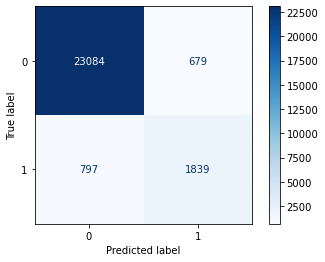

In [103]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0,1])
disp.plot(cmap='Blues')
None

In [104]:
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt
y_pred_proba = gbc.predict_proba(X_test)[:, 1]


roc_auc = roc_auc_score(y_test, y_pred_proba)
print(f"ROC AUC Score on Test Set: {roc_auc:.4f}")

ROC AUC Score on Test Set: 0.9618


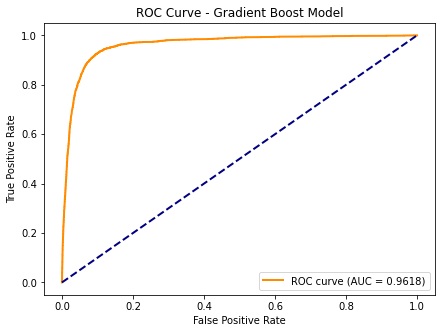

In [105]:
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Gradient Boost Model')
plt.legend(loc='lower right')
plt.show()

### Conclusion:

#### When compared to the logistic regression models I carried out in previous homeworks, the Gradient Boost model surprisingly underperformed the Logistic regression on Recall (in particular Logistic regression with Elastic Net).


| Model                              | Test Recall (Class 1 = Default) | Notes                      |
| ---------------------------------- | ------------------------------- | -------------------------- |
| Logistic Regression (and variants) |from **0.912 – 0.915**             | Very high recall           |
| Gradient Boost                     | **0.70**                        | Substantially lower recall |


#### Gradient Boost has higher overall accuracy (0.94) and better precision for class 1 (0.73 vs 0.54).
#### However, in an imbalanced dataset, accuracy can be misleading: predicting most loans as “non-default” can result in a high accuracy score even with poor minority class performance due to the inherant class imbalances.


#### To get a better recall–precision balance, going forward I intend to explore the following:
#### 1. adjusting the classification threshold (probability threshold that affects the class label) of my Gradient Boost model (as explained in this article:https://machinelearningmastery.com/threshold-moving-for-imbalanced-classification), and/or
#### 2. applying class weighting / SMOTE to improve recall without losing too much precision. (as explained in this article: https://www.geeksforgeeks.org/machine-learning/smote-for-imbalanced-classification-with-python)

### NOTE to Myself

Use metrics sensitive to TPR, like:
Recall / Sensitivity
F1-score (balances TPR and precision)
Precision-Recall curves (PR-AUC) rather than ROC-AUC when dataset is imbalanced
Consider resampling techniques:
Oversample the minority class (SMOTE, random oversampling)
Undersample the majority class
Threshold adjustment:
Move decision threshold lower to increase TPR at the cost of some FPR.